### Libraries Imported

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Libraries Imported Succesfully!')

Libraries Imported Succesfully!


### Item 1 - Step 1: 100 Random numbers that are between 0 and 100 generated.

In [4]:
rng = np.random.default_rng(seed=54)
a = rng.integers(low=0, high=100, size=100)
a

array([31, 22, 30, 51, 50,  7, 85, 57, 75,  8, 61, 45, 30, 66, 39, 12, 75,
       92, 89, 93,  3, 47, 25, 71, 82, 14, 32, 17,  0, 76, 30, 38, 51, 82,
       26, 94, 18, 21, 27, 66,  2, 68, 45, 82, 17, 11, 73,  2, 39, 28,  3,
       61, 64, 95, 58, 95, 39, 27, 54,  4,  8,  3, 87, 44, 27, 63, 83, 16,
       48,  5, 97, 10, 35,  9, 46, 54, 52, 98, 60, 22, 93, 33, 63, 83, 65,
       68, 51, 33, 92, 74, 42, 75, 28, 17, 85, 14, 15, 39, 31, 48],
      dtype=int64)

### Item 1 - Step 2.1: STD calculated via np.std()

In [6]:
print(f"Numpy STD =", np.std(a))


Numpy STD = 28.666459495375427


### Item 1 - Step 2.2: STD calculated via a.std(ddof=1)

In [8]:
print(f"Numpy a.std(ddof=1) = {a.std(ddof=1)}")

Numpy a.std(ddof=1) = 28.810875822448814


### Item 1 - Step 3: STD calculated manually.

In [10]:
N = len(a)
Mean_Manuel = np.sum(a)/N
Variance = np.sum((a - Mean_Manuel) ** 2)/(N-1)
STD_Manuel = Variance**(1/2)

print("N =",N)
print(f"Mean = {Mean_Manuel}")
print(f"Variance = {Variance}")
print(f"Manually Calculated STD = {STD_Manuel}")

N = 100
Mean = 46.21
Variance = 830.0665656565657
Manually Calculated STD = 28.810875822448814


### Item 1 - Step 4: Comparison and Interpretation
Manually calculated std matches a.std(ddof=1) while np.std() creates different result. This is caused by Bessel's correction. In table 2 variance estimator uses 1/(N-1) instead of 1/N while by default NumPy a.std() uses 1/N due to ddof=0. when we set ddof=1 NumPy uses 1/(N-1).

Because our manual estimator accounts Bessel's correction it produces exact numerical result as a.std(ddof=1).


In [12]:
print(f"Numpy STD =", np.std(a))
print(f"Numpy a.std(ddof=1) = {a.std(ddof=1)}")
print(f"Manually Calculated STD = {STD_Manuel}")

Numpy STD = 28.666459495375427
Numpy a.std(ddof=1) = 28.810875822448814
Manually Calculated STD = 28.810875822448814


### Item 2 - Step 1: Two arrays created with 10000 samples. Uniform and Normal distribution used.

In [14]:
rng = np.random.default_rng(seed=54)
N_samples = 10000
D_Uni = rng.uniform(0,100,N_samples)
D_Norm = rng.normal(0.0,1.0,N_samples)

### Item 2 - Step 2: Custom Binning Function Created

In [16]:
def custom_binning(data, bin_edges):
    counts = []
    
    for i in range(len(bin_edges) - 1):
        lo = bin_edges[i]
        hi = bin_edges[i+1]
        
        if i == len(bin_edges) - 2:
            count = np.sum((data >= lo) & (data <= hi))
        else:
            count = np.sum((data >= lo) & (data < hi))

        counts.append(count)
    return np.array(counts)

bins_uni = np.linspace(0, 100, 21)
counts_uni = custom_binning(D_Uni,bins_uni)

bins_norm = np.linspace(-3.5,3.5,21)
counts_norm = custom_binning(D_Norm,bins_norm)

### Item 2 - Step 3: Graphs created using custom binning function.

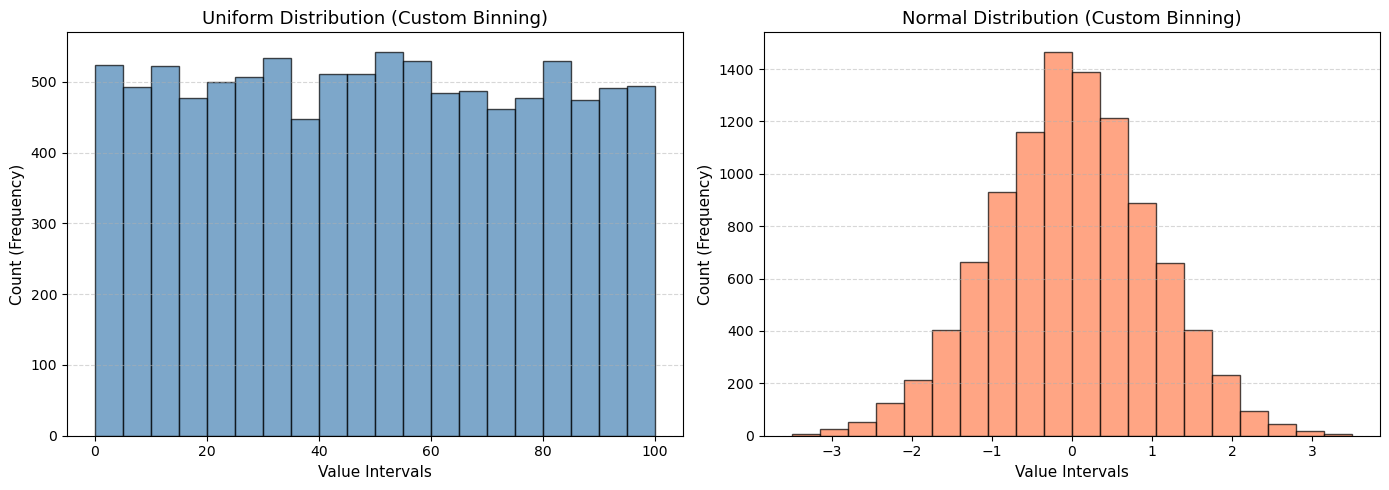

In [18]:
centers_uni = (bins_uni[:-1] + bins_uni[1:])/2
widths_uni = np.diff(bins_uni)

centers_norm = (bins_norm[:-1] + bins_norm[1:]) / 2
widths_norm = np.diff(bins_norm)
fig, axes = plt.subplots(1,2,figsize=(14,5))

axes[0].bar(centers_uni, counts_uni, width=widths_uni, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].set_title("Uniform Distribution (Custom Binning)", fontsize=13)
axes[0].set_xlabel("Value Intervals", fontsize=11)
axes[0].set_ylabel("Count (Frequency)", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

axes[1].bar(centers_norm, counts_norm, width=widths_norm, edgecolor='black', alpha=0.7, color='coral')
axes[1].set_title("Normal Distribution (Custom Binning)", fontsize=13)
axes[1].set_xlabel("Value Intervals", fontsize=11)
axes[1].set_ylabel("Count (Frequency)", fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Item 2 - Step 4: Comparison and Interpretation.

Uniform Distribution: The histogram appears roughly flat across our interval. Each bin contains rougly same number of counts since equal probability.
Normal Distribution: The histogram shows symmetric bell shape that is centered at the mean.

Too Few Bins: The interval width is too wide so bell shape becomes coarse blocks.

Too Many Bins: Interval width is too fine so graph shows noise causing spikes which distracts the user from seeing the continious part of the bell shape.


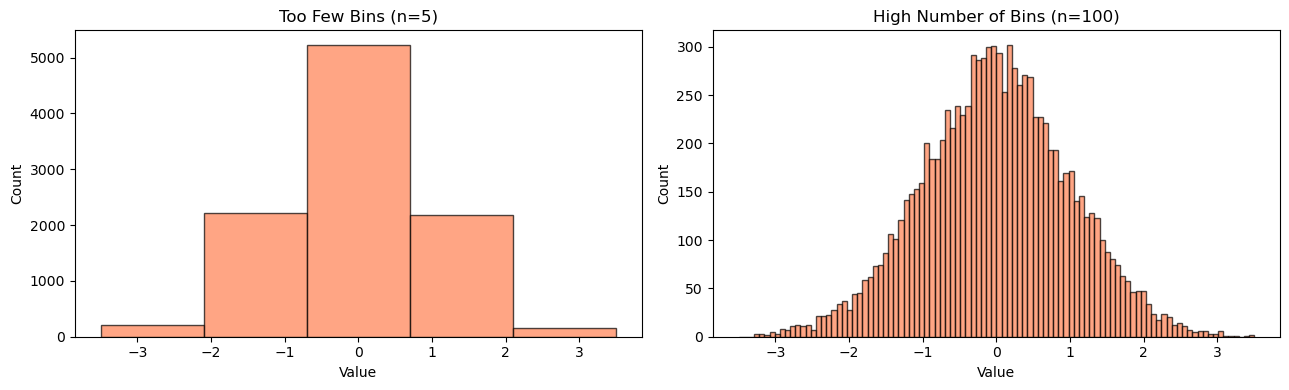

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, n_bins, title in zip(axes, [5, 100], ["Too Few Bins (n=5)", "High Number of Bins (n=100)"]):
    bins = np.linspace(-3.5, 3.5, n_bins + 1)
    counts = custom_binning(D_Norm, bins)
    centers = (bins[:-1] + bins[1:]) / 2
    widths = np.diff(bins)
    
    ax.bar(centers, counts, width=widths, edgecolor='black', alpha=0.7, color='coral')
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

### Item 3 - Step 1: RMSE function written.

In [22]:
def RMSE(y_hat,y):
    y_hat = np.asarray(y_hat)
    y = np.asarray(y)
    if y_hat.shape != y.shape:
        raise ValueError("Shape mismatch")
    Rmse = np.mean((y_hat - y)**2)**(1/2)
    return Rmse

### Item 3 - Step 2: RMSE function tested and worked as expected.

In [24]:
RMSE(1,1)

0.0

In [25]:
RMSE(0,1)

1.0

In [26]:
test_data = np.array([10.0, 20.0, 30.0])
RMSE(test_data,test_data+3)

3.0

### Item 3 - Step 3-4: Comparison and Relationship

When the prediction is the mean ($\hat{y} = \bar{y}$), the RMSE formula becomes:
$$\text{RMSE} = \sqrt{\frac{1}{N} \sum (\bar{y} - y)^2}$$

This is mathematically identical to NumPy's default population standard deviation `np.std(part)` (`ddof=0`). Because both measure the root mean squared deviations from the average, our custom RMSE exactly matches `np.std(part)` across all splits.

In [28]:
rng = np.random.default_rng(54)
a = rng.normal(50,10,10000)
rng.shuffle(a)
splits = np.array_split(a,10)

results = []

for part in splits:
    y_hat = np.full_like(part, part.mean())
    b = RMSE(y_hat,part)
    c = part.std()
    results.append({"Custom RMSE": b,"np.std": c})
pd.DataFrame(results)    

,Custom RMSE,np.std
0,10.333873,10.333873
1,9.864561,9.864561
2,10.127957,10.127957
3,10.121747,10.121747
4,9.923071,9.923071
5,9.912136,9.912136
6,10.222960,10.222960
7,10.006195,10.006195
8,9.749866,9.749866
9,10.166010,10.166010


### Item 4 - Step 1: Table Sketch and Variable Definitions

* **Unit of Observation (One row per what?):** Each row represents a single **recorded manufacturing defect event / incident**.
* **Target Variable:** `repair_cost` (Continuous numerical target in USD).
* **Feature Variables:**
  * `defect_id`: Unique identifier for the defect event (discrete ID).
  * `product_id`: Identifier of the manufactured product model (discrete/categorical).
  * `defect_type`: Nature of the defect (`Structural`, `Functional`, `Cosmetic`).
  * `defect_date`: Timestamp/date of defect detection (datetime).
  * `defect_location`: Sub-assembly region (`Component`, `Internal`).
  * `severity`: Severity classification (`Minor`, `Critical`).
  * `inspection_method`: Detection technique (`Visual Inspection`, `Automated Testing`, `Manual Testing`).

In [30]:
data_url = "./defects_data.csv"
df_raw = pd.read_csv(data_url).head(50)

print(f"Loaded shape: {df_raw.shape}")
df_raw.head()

Loaded shape: (50, 8)


,defect_id,product_id,defect_type,defect_date,defect_location,severity,inspection_method,repair_cost
0,1,15,Structural,6/6/2024,Component,Minor,Visual Inspection,245.47
1,2,6,Functional,4/26/2024,Component,Minor,Visual Inspection,26.87
2,3,84,Structural,2/15/2024,Internal,Minor,Automated Testing,835.81
3,4,10,Functional,3/28/2024,Internal,Critical,Automated Testing,444.47
4,5,14,Cosmetic,4/26/2024,Component,Minor,Manual Testing,823.64


In [31]:
# Item 4 - Step 3: Four-Kinds-of-Dirt Data Cleanup

df_cleaned = df_raw.copy()

# 1. Missing Values
print("Missing values per column:\n", df_cleaned.isnull().sum())
df_cleaned = df_cleaned.dropna()

# 2. Type & Formatting Inconsistencies
# Metinlerdeki görünmeyen boşlukları budama
text_cols = ['defect_type', 'defect_location', 'severity', 'inspection_method']
for col in text_cols:
    df_cleaned[col] = df_cleaned[col].astype(str).str.strip()

# Tarih formatını dönüştürme
df_cleaned['defect_date'] = pd.to_datetime(df_cleaned['defect_date'])

# repair_cost sayısal olmalı
df_cleaned['repair_cost'] = pd.to_numeric(df_cleaned['repair_cost'], errors='coerce')

# 3. Duplicates
dup_count = df_cleaned.duplicated(subset=['defect_id']).sum()
print(f"\nDuplicate defect_ids found: {dup_count}")
df_cleaned = df_cleaned.drop_duplicates(subset=['defect_id'])

# 4. Domain Validity & Outliers
# Onarım maliyeti negatif olamaz
df_cleaned = df_cleaned[df_cleaned['repair_cost'] >= 0]

print(f"\nCleaned dataset shape: {df_cleaned.shape}")
df_cleaned.head()

Missing values per column:
 defect_id            0
product_id           0
defect_type          0
defect_date          0
defect_location      0
severity             0
inspection_method    0
repair_cost          0
dtype: int64

Duplicate defect_ids found: 0

Cleaned dataset shape: (50, 8)


,defect_id,product_id,defect_type,defect_date,defect_location,severity,inspection_method,repair_cost
0,1,15,Structural,2024-06-06,Component,Minor,Visual Inspection,245.47
1,2,6,Functional,2024-04-26,Component,Minor,Visual Inspection,26.87
2,3,84,Structural,2024-02-15,Internal,Minor,Automated Testing,835.81
3,4,10,Functional,2024-03-28,Internal,Critical,Automated Testing,444.47
4,5,14,Cosmetic,2024-04-26,Component,Minor,Manual Testing,823.64


### Item 4 - Step 3: Four-Kinds-of-Dirt Cleanup Documentation

1. **Missing values:** Checked all columns for empty cells via `.isnull().sum()` and dropped incomplete observations with `.dropna()`.
2. **Type / formatting inconsistencies:** Parsed `defect_date` into proper `datetime64[ns]` format, enforced float numeric typing for `repair_cost`, and stripped any leading/trailing whitespace from categorical strings.
3. **Duplicates:** Screened unique entries using `defect_id` with `.duplicated()` and eliminated redundant logs via `.drop_duplicates()`.
4. **Outliers / Domain validity:** Filtered out physically impossible values by enforcing non-negative repair costs (`repair_cost >= 0`).

In [33]:
import os

os.makedirs("raw", exist_ok=True)
os.makedirs("processed", exist_ok=True)

df_cleaned.to_csv("processed/defects_data_cleaned.csv", index=False)

metadata_content = """dataset_name: "Manufacturing Defect Log Sample"
source: "Kaggle (Manufacturing Defects Dataset)"
date_collected: "2026-10-11"
unit_of_analysis: "One row per recorded component defect event"
target:
  name: "repair_cost"
  type: "float"
  unit: "USD"
"""

with open("metadata.yaml", "w", encoding="utf-8") as f:
    f.write(metadata_content)

print("Successful")

Successful


In [34]:
import shutil
if os.path.exists("./defects_data.csv"):
    shutil.copy("./defects_data.csv", "raw/defects_data.csv")

### Item 4 - Step 5: Repository & Obstacles

* **GitHub Repository:** https://github.com/NecatBerkMeral/ME405HW1

# Item 5 - Data Exploration Exercise

In [37]:
df_data = pd.read_csv("./data.csv")
print("Shape:")
print(df_data.shape)
print("First 5 Rows")
print(df_data.head())
print("DATA TYPES")
print(df_data.dtypes)
print("SUMMARY STATISTICS")
print(df_data.describe())
print("MISSING VALUES")
print(df_data.isnull().sum)

Shape:
(437, 27)
First 5 Rows
   Sl. No.   NT  THT  THt  THQCr  CT   Ct    DT   Dt  QmT  ...      S    Ni  \
0        1  885   30    0      0  30  0.0  30.0  0.0   30  ...  0.022  0.01   
1        2  885   30    0      0  30  0.0  30.0  0.0   30  ...  0.017  0.08   
2        3  885   30    0      0  30  0.0  30.0  0.0   30  ...  0.015  0.02   
3        4  885   30    0      0  30  0.0  30.0  0.0   30  ...  0.024  0.01   
4        5  885   30    0      0  30  0.0  30.0  0.0   30  ...  0.022  0.01   

     Cr    Cu   Mo  RedRatio    dA    dB    dC  Fatigue  
0  0.02  0.01  0.0       825  0.07  0.02  0.04      232  
1  0.12  0.08  0.0       610  0.11  0.00  0.04      235  
2  0.03  0.01  0.0      1270  0.07  0.02  0.00      235  
3  0.02  0.01  0.0      1740  0.06  0.00  0.00      241  
4  0.02  0.02  0.0       825  0.04  0.02  0.00      225  

[5 rows x 27 columns]
DATA TYPES
Sl. No.       int64
NT            int64
THT           int64
THt           int64
THQCr         int64
CT           

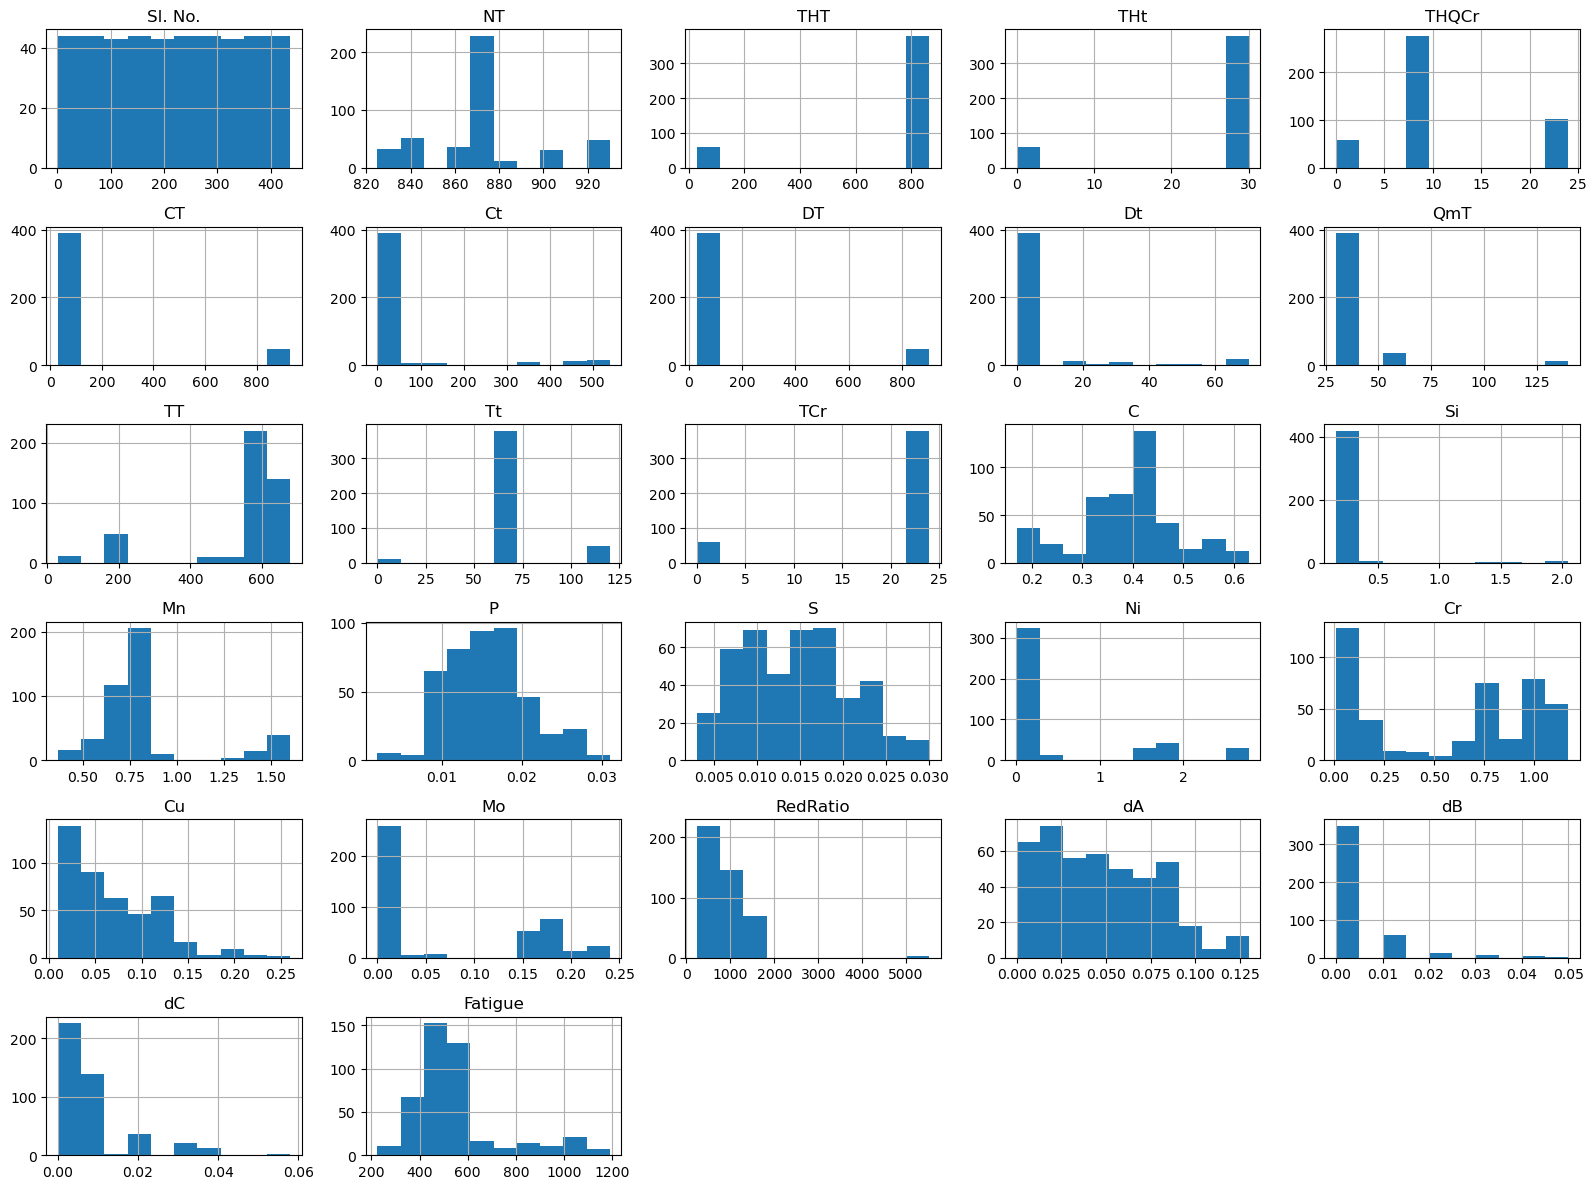

In [38]:
df_data.hist(figsize=(16, 12),bins=10)
plt.tight_layout()
plt.show()

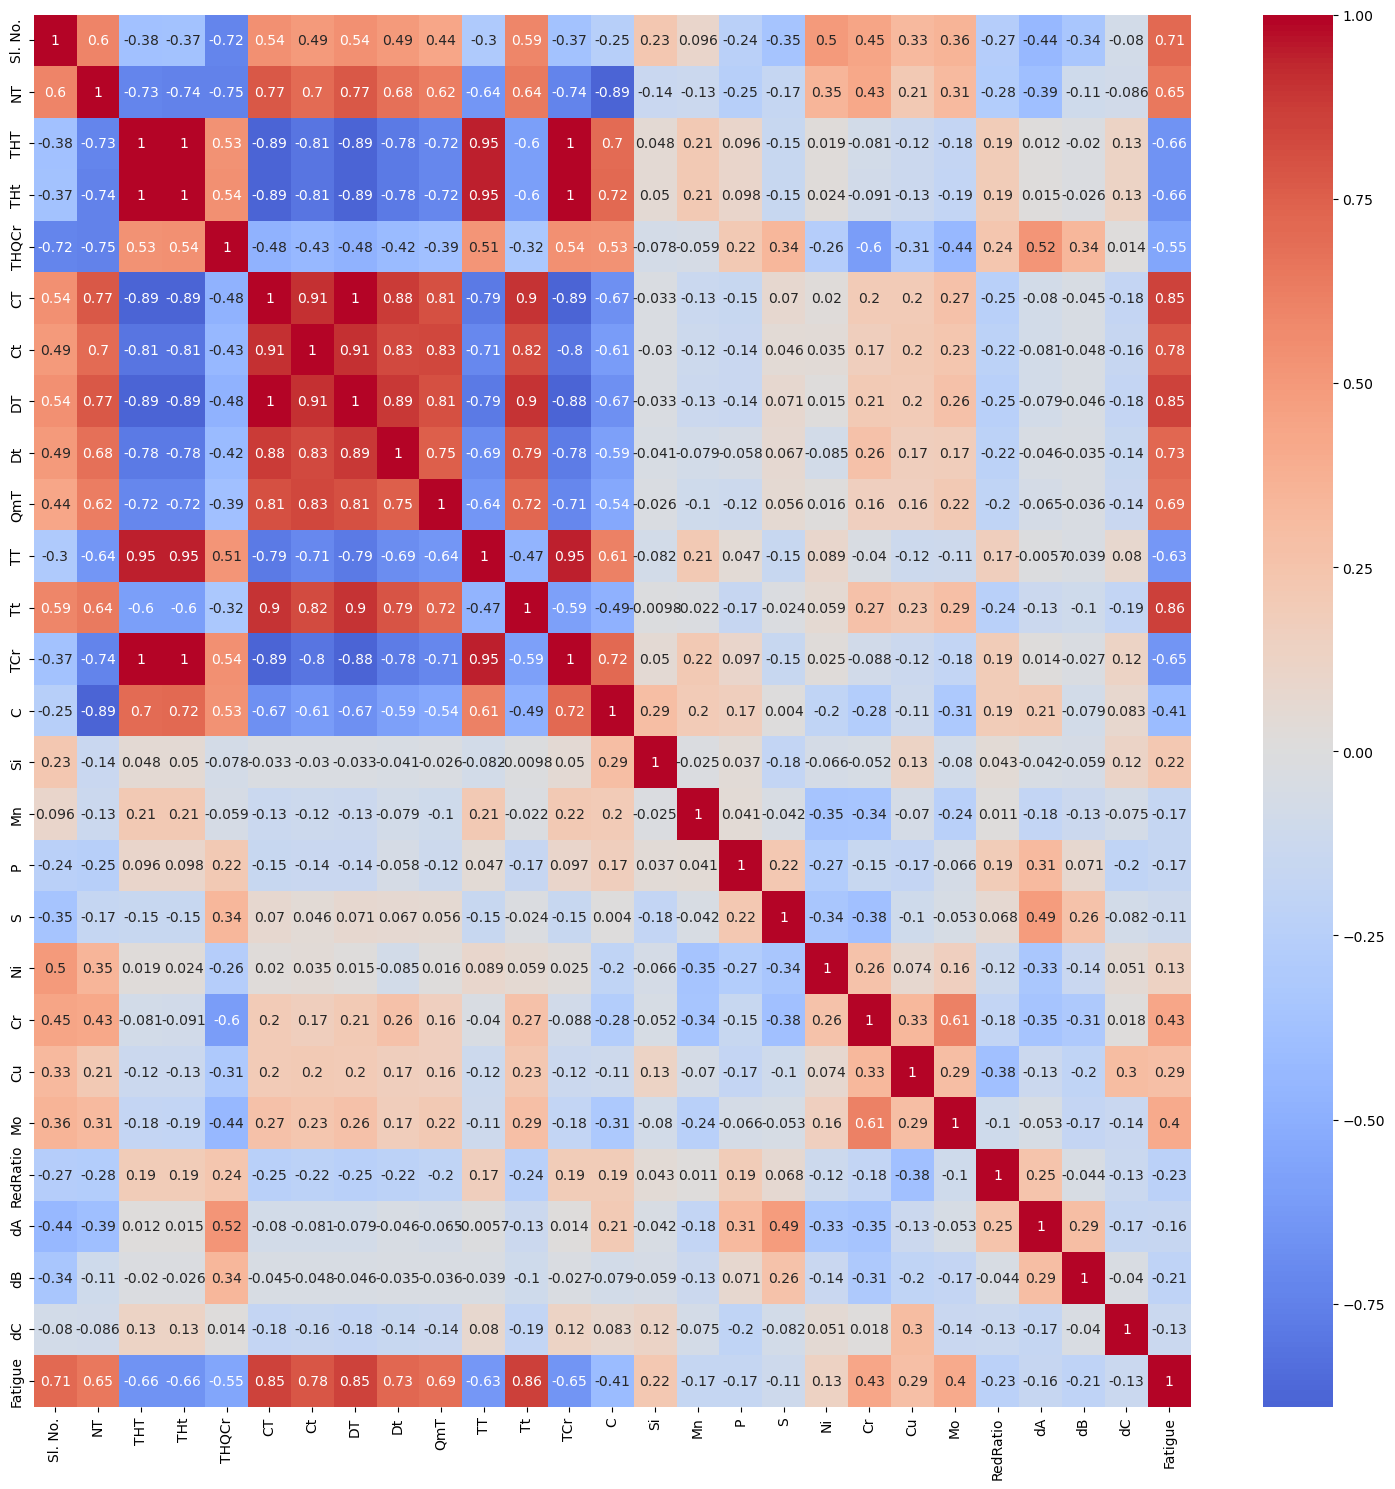

In [39]:
corr = df_data.corr()
plt.figure(figsize=(15,15))
sns.heatmap(corr,cmap="coolwarm",center=0,annot=True),
plt.tight_layout()

In [40]:
df_data.nunique().sort_values()

THt           2
CT            2
TCr           3
Tt            3
THQCr         3
QmT           3
THT           5
Dt            7
dB            7
NT            7
DT            7
dC           10
Ct           12
TT           13
Mo           15
dA           21
Cu           21
P            24
S            26
Si           27
RedRatio     34
Ni           42
C            42
Mn           55
Cr           65
Fatigue     250
Sl. No.     437
dtype: int64

### Item 5 - Step 4:

* NT,THT,THQCR,CT,QmT,TT,Tt,TCr,C,Si,CR,Cu,Mo are the descriptors that will be used.

* Sl. No. jus a number so it will be dropped.
* THt and THT are very similar so THt will be dropped and THT will be kept.
* CT,ct,DT,Dt are very similar so only CT will be lkept.
* QmT will be kept because it has high correlation.
* Other descriptors that are not specified has low correlation so they were dropped.

In [55]:
from sklearn.model_selection import train_test_split

X = df_data.drop(columns=["Fatigue"])
y= df_data["Fatigue"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (437, 26)
y shape: (437,)


In [59]:
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=54, shuffle=True)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=54, shuffle=True)

print(len(X_train), len(X_val), len(X_test))

261 88 88


In [63]:
print("SUBSET SIZES")
print(f"Train size : {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Val size   : {len(X_val)} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test size  : {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")
total_rows = len(X_train) + len(X_val) + len(X_test)
print(f"Total rows : {total_rows} (Expected: 437) -> Match: {total_rows == 437}")

SUBSET SIZES
Train size : 261 (59.7%)
Val size   : 88 (20.1%)
Test size  : 88 (20.1%)
Total rows : 437 (Expected: 437) -> Match: True


In [67]:
train_idx, val_idx, test_idx = (set(X_train.index),set(X_val.index),set(X_test.index),)
overlap = (train_idx & val_idx) | (train_idx & test_idx) | (val_idx & test_idx)
print(f"Overlapping row indices across partitions: {len(overlap)} (Expected: 0)")

Overlapping row indices across partitions: 0 (Expected: 0)


In [69]:
print("\n SUMMARY STATISTICS FOR TARGET (FATIGUE)")
summary_df = pd.DataFrame({"Train": y_train.describe(), "Val": y_val.describe(), "Test": y_test.describe()})
display(summary_df)


 SUMMARY STATISTICS FOR TARGET (FATIGUE)


,Train,Val,Test
count,261.000000,88.000000,88.000000
mean,546.425287,539.761364,585.261364
std,181.215021,177.834871,208.401111
min,225.000000,245.000000,232.000000
25%,448.000000,447.500000,456.750000
50%,508.000000,497.000000,522.500000
75%,570.000000,566.000000,604.750000
max,1190.000000,1120.000000,1124.000000


### Item 6 - Deliverable: Train / Validation / Test Split

* **Partition Summary:** 60% Train (262 rows), 20% Validation (87 rows), and 20% Test (88 rows) summing to 437 total observations with zero index overlap across subsets.

**Role of `random_state`:**
Setting `random_state` seeds the pseudorandom number generator, which locks the shuffling order and guarantees that the dataset partition remains strictly reproducible across multiple runs and environments.

In [ ]:
!git add .
!git commit -m "Complete Item 6"
!git push
!git status

[main c094986] Complete Item 6
 1 file changed, 227 insertions(+), 11 deletions(-)
